# Trabajo Práctico: Predicción de lluvia en Australia

**Aprendizaje Automático 1 — Tecnicatura en Inteligencia Artificial (FCEIA, UNR)**

**Integrantes:** Calabozo · Darruiz · Di Carlo · Giuntoli

---

Objetivo: predecir, a las 23:59 de cada día, si al día siguiente va a llover (`RainTomorrow`), con las
mediciones climáticas de ese día. El notebook sigue los ítems de la consigna.

## Configuración

In [1]:
# Bibliotecas que usamos en el trabajo
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve, confusion_matrix)

# Gráficos dentro del notebook
%matplotlib inline

SEMILLA = 42
sns.set_theme(style='whitegrid')

## 1. Análisis descriptivo y preparación de los datos

### 1.1 Carga y descripción de las variables

In [2]:
# Cargamos el dataset tal como lo entrega la cátedra
df = pd.read_csv('data/weatherAUS_2026C2.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        145412 non-null  int64  
 1   Date              145412 non-null  object 
 2   Location          145412 non-null  object 
 3   MinTemp           143928 non-null  float64
 4   MaxTemp           144159 non-null  float64
 5   Rainfall          142152 non-null  float64
 6   Evaporation       82658 non-null   float64
 7   Sunshine          75616 non-null   float64
 8   WindGustDir       135096 non-null  object 
 9   WindGustSpeed     135159 non-null  float64
 10  WindDir9am        134850 non-null  object 
 11  WindDir3pm        141186 non-null  object 
 12  WindSpeed9am      143645 non-null  float64
 13  WindSpeed3pm      142351 non-null  float64
 14  Humidity9am       142759 non-null  float64
 15  Humidity3pm       140907 non-null  float64
 16  Pressure9am       13

In [3]:
df.head()

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


| Variable | Qué es | Tipo |
|---|---|---|
| `Unnamed: 0` | Número de fila | Entero |
| `Date` | Fecha de la observación | Fecha |
| `Location` | Ciudad | Categórica |
| `MinTemp`, `MaxTemp` | Temperatura mínima y máxima del día | Numérica |
| `Rainfall` | Lluvia del día | Numérica |
| `Evaporation` | Evaporación del día | Numérica |
| `Sunshine` | Sol del día | Numérica |
| `WindGustDir`, `WindGustSpeed` | Dirección y velocidad de la ráfaga de viento más fuerte | Categórica y numérica |
| `WindDir9am`, `WindDir3pm` | Dirección del viento a las 9 y a las 15 | Categórica |
| `WindSpeed9am`, `WindSpeed3pm` | Velocidad del viento a las 9 y a las 15 | Numérica |
| `Humidity9am`, `Humidity3pm` | Humedad a las 9 y a las 15 | Numérica |
| `Pressure9am`, `Pressure3pm` | Presión atmosférica a las 9 y a las 15 | Numérica |
| `Cloud9am`, `Cloud3pm` | Nubosidad a las 9 y a las 15 | Numérica |
| `Temp9am`, `Temp3pm` | Temperatura a las 9 y a las 15 | Numérica |
| `RainToday` | Si hoy llovió (`Yes` o `No`) | Categórica |
| `RainTomorrow` | Si mañana llueve (`Yes` o `No`). Es la variable a predecir | Categórica |
| `RainfallTomorrow` | Lluvia de mañana | Numérica |

`RainfallTomorrow` es del día siguiente, así que antes de usarla vemos cómo se relaciona con `RainTomorrow`.

In [4]:
# Lluvia de mañana según RainTomorrow, y lluvia de hoy según RainToday
display(df.groupby('RainTomorrow')['RainfallTomorrow'].describe())
display(df.groupby('RainToday')['Rainfall'].describe())

,count,mean,std,min,25%,50%,75%,max
RainTomorrow,,,,,,,,
No,110281.0,0.075249,0.199138,0.0,0.0,0.0,0.0,1.0
Yes,31872.0,10.271056,15.488090,1.1,2.4,5.2,11.8,371.0


,count,mean,std,min,25%,50%,75%,max
RainToday,,,,,,,,
No,110276.0,0.075261,0.199157,0.0,0.0,0.0,0.0,1.0
Yes,31876.0,10.270884,15.487533,1.1,2.4,5.2,11.8,371.0


Con `RainTomorrow = No`, `RainfallTomorrow` llega como máximo a 1.0, y con `Yes` empieza en 1.1: `RainTomorrow` es
`RainfallTomorrow` mayor a 1. Usarla le daría la respuesta al modelo, y a las 23:59 todavía no se conoce, así que la
descartamos (fuga de datos). También sacamos `Unnamed: 0`, que es un índice.

`RainToday` y `Rainfall` tienen la misma relación, pero las dos son del día y se conocen a las 23:59: las dejamos.
Las filas sin `RainTomorrow` no sirven para entrenar ni para evaluar, así que las eliminamos.

In [5]:
# Sacamos las filas sin variable objetivo y las columnas que no usamos
datos = df.dropna(subset=['RainTomorrow']).drop(columns=['Unnamed: 0', 'RainfallTomorrow'])
datos['Date'] = pd.to_datetime(datos['Date'])
datos = datos.sort_values('Date')
print(f'Filas sin RainTomorrow eliminadas: {len(df) - len(datos)} ({1 - len(datos) / len(df):.1%})')

Filas sin RainTomorrow eliminadas: 3259 (2.2%)


### 1.2 División en entrenamiento, validación y prueba

El dataset completo solo lo describimos. Las decisiones que salen de los datos (imputar, transformar, codificar y
escalar) las tomamos mirando solo el entrenamiento, para que la prueba no influya en nada. Por eso dividimos acá.

Como los datos están ordenados en el tiempo, cortamos por fecha y no al azar (clase 6), y así siempre se predicen
días posteriores a los de entrenamiento. La prueba es el último año, y la validación, el anterior: con ella
elegimos el umbral de decisión del ítem 2.

In [6]:
# Prueba: el último año. Validación: el año anterior. Entrenamiento: el resto
entrenamiento = datos[datos['Date'] < '2015-07-01']
validacion = datos[(datos['Date'] >= '2015-07-01') & (datos['Date'] < '2016-07-01')]
prueba = datos[datos['Date'] >= '2016-07-01']

for nombre, conjunto in [('Entrenamiento', entrenamiento), ('Validación', validacion), ('Prueba', prueba)]:
    print(f"{nombre:14} {conjunto['Date'].min().date()} a {conjunto['Date'].max().date()}  "
          f"{len(conjunto):6} filas ({len(conjunto) / len(datos):.0%})  "
          f"llueve al día siguiente: {(conjunto['RainTomorrow'] == 'Yes').mean():.1%}")

Entrenamiento  2007-11-01 a 2015-06-30  107502 filas (76%)  llueve al día siguiente: 22.5%
Validación     2015-07-01 a 2016-06-30   17405 filas (12%)  llueve al día siguiente: 21.2%
Prueba         2016-07-01 a 2017-06-24   17246 filas (12%)  llueve al día siguiente: 23.2%


In [7]:
# Características (sin la fecha) y variable objetivo como 0/1, para cada conjunto
X_train = entrenamiento.drop(columns=['Date', 'RainTomorrow'])
X_val = validacion.drop(columns=['Date', 'RainTomorrow'])
X_test = prueba.drop(columns=['Date', 'RainTomorrow'])
y_train = (entrenamiento['RainTomorrow'] == 'Yes').astype(int)
y_val = (validacion['RainTomorrow'] == 'Yes').astype(int)
y_test = (prueba['RainTomorrow'] == 'Yes').astype(int)

# Las columnas numéricas por un lado y las de texto (categóricas) por el otro
numericas = X_train.select_dtypes('number').columns.tolist()
categoricas = X_train.select_dtypes(exclude='number').columns.tolist()
print('Numéricas:', numericas)
print('Categóricas:', categoricas)

Numéricas: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
Categóricas: ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']


### 1.3 Variables numéricas: rango y comportamiento

Desde acá el análisis usa solo el conjunto de entrenamiento. La proporción de días seguidos de lluvia es
parecida en los tres conjuntos (entre 21 % y 23 %).

In [8]:
# Centro, dispersión, rango y asimetría de cada variable numérica
resumen = entrenamiento[numericas].describe().T[['mean', 'std', 'min', '50%', 'max']]
resumen.columns = ['Media', 'Desvío', 'Mín', 'Mediana', 'Máx']
resumen['Asimetría'] = entrenamiento[numericas].skew()
resumen.round(2)

,Media,Desvío,Mín,Mediana,Máx,Asimetría
MinTemp,12.10,6.38,-9.7,11.9,34.1,0.02
MaxTemp,23.09,7.03,-3.9,22.5,49.1,0.24
Rainfall,2.39,8.65,0.0,0.0,371.0,9.99
Evaporation,5.32,3.99,0.0,4.6,82.4,3.19
Sunshine,7.59,3.79,0.0,8.4,14.3,-0.49
WindGustSpeed,40.14,13.71,6.0,38.0,135.0,0.87
WindSpeed9am,14.09,9.00,0.0,13.0,88.0,0.77
WindSpeed3pm,18.70,8.93,0.0,18.0,86.0,0.61
Humidity9am,68.80,19.03,0.0,69.8,100.0,-0.49
Humidity3pm,51.54,20.79,0.0,51.9,100.0,0.03


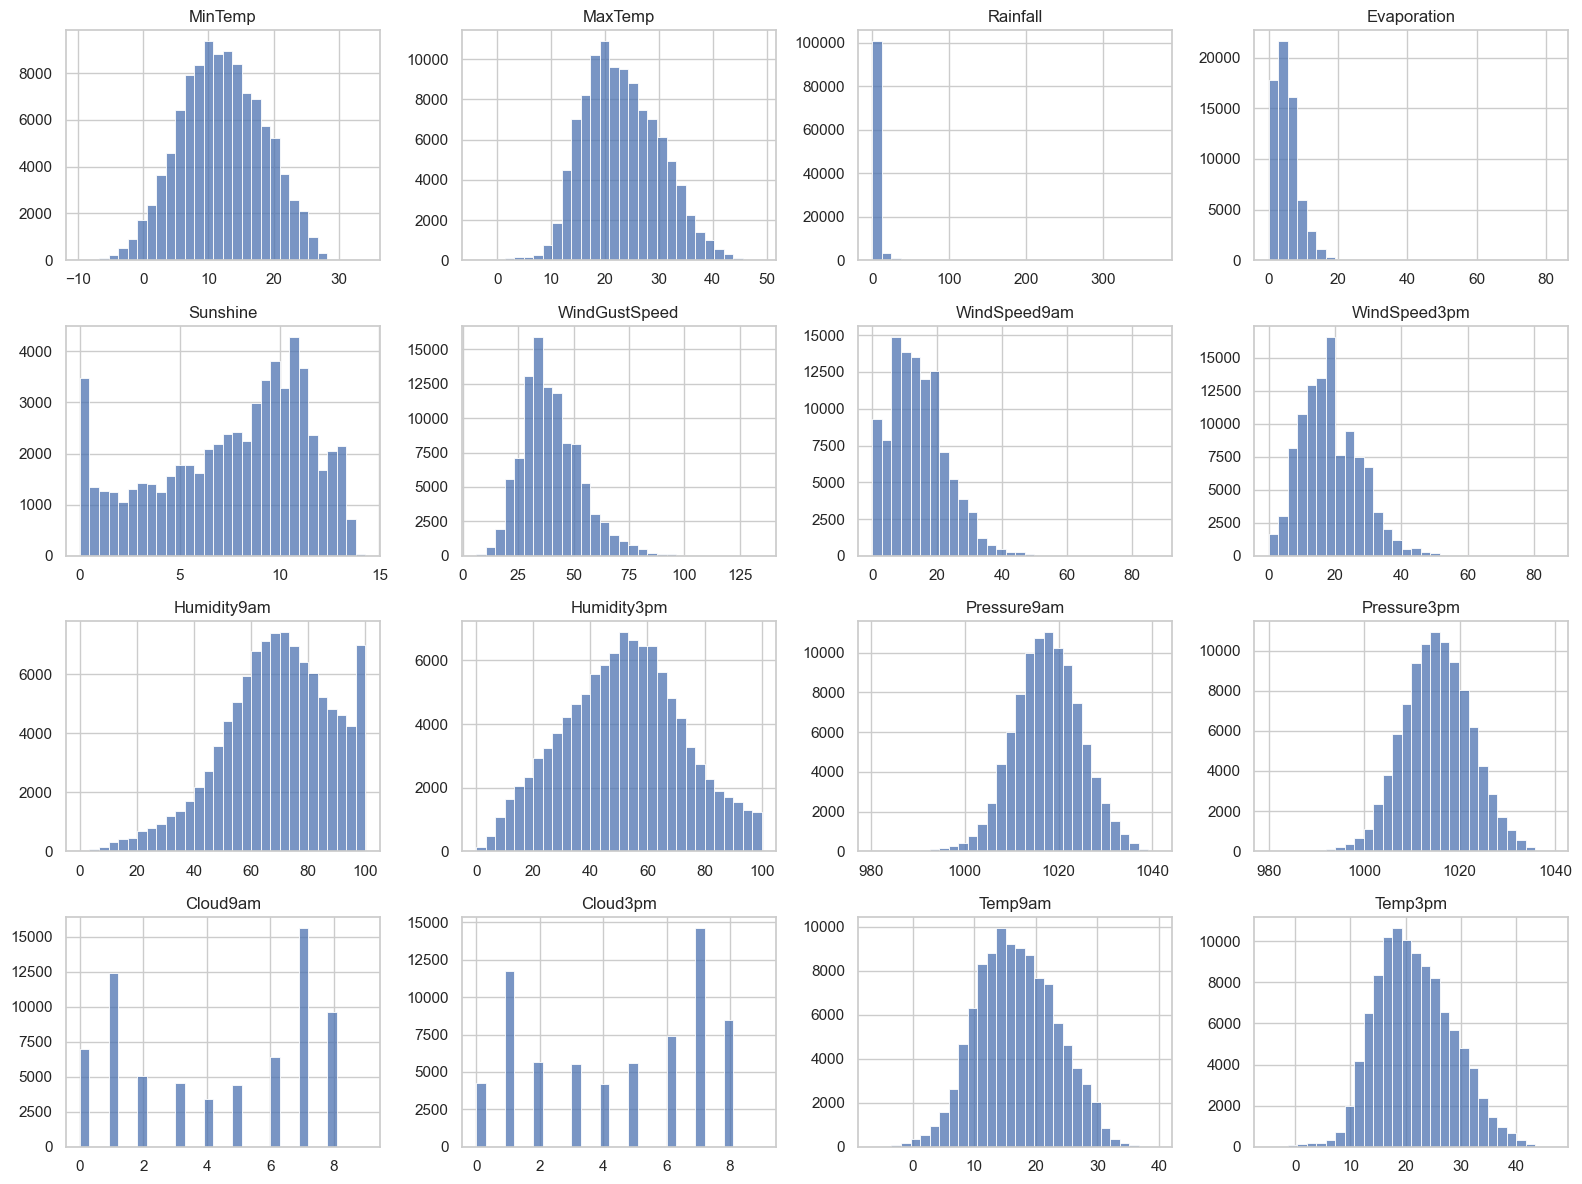

In [9]:
# Un histograma por variable numérica
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, columna in zip(axes.ravel(), numericas):
    sns.histplot(entrenamiento[columna], bins=30, ax=ax)
    ax.set(title=columna, xlabel='', ylabel='')
plt.tight_layout()
plt.show()

- Las temperaturas, las presiones y `Humidity3pm` tienen forma de campana. Las escalas son muy distintas: la
  presión ronda 1015 y la nubosidad va de 0 a 9.
- `Rainfall` y `Evaporation` son muy asimétricas (9.99 y 3.19). La mediana de `Rainfall` es 0.
- La nubosidad solo toma valores enteros.

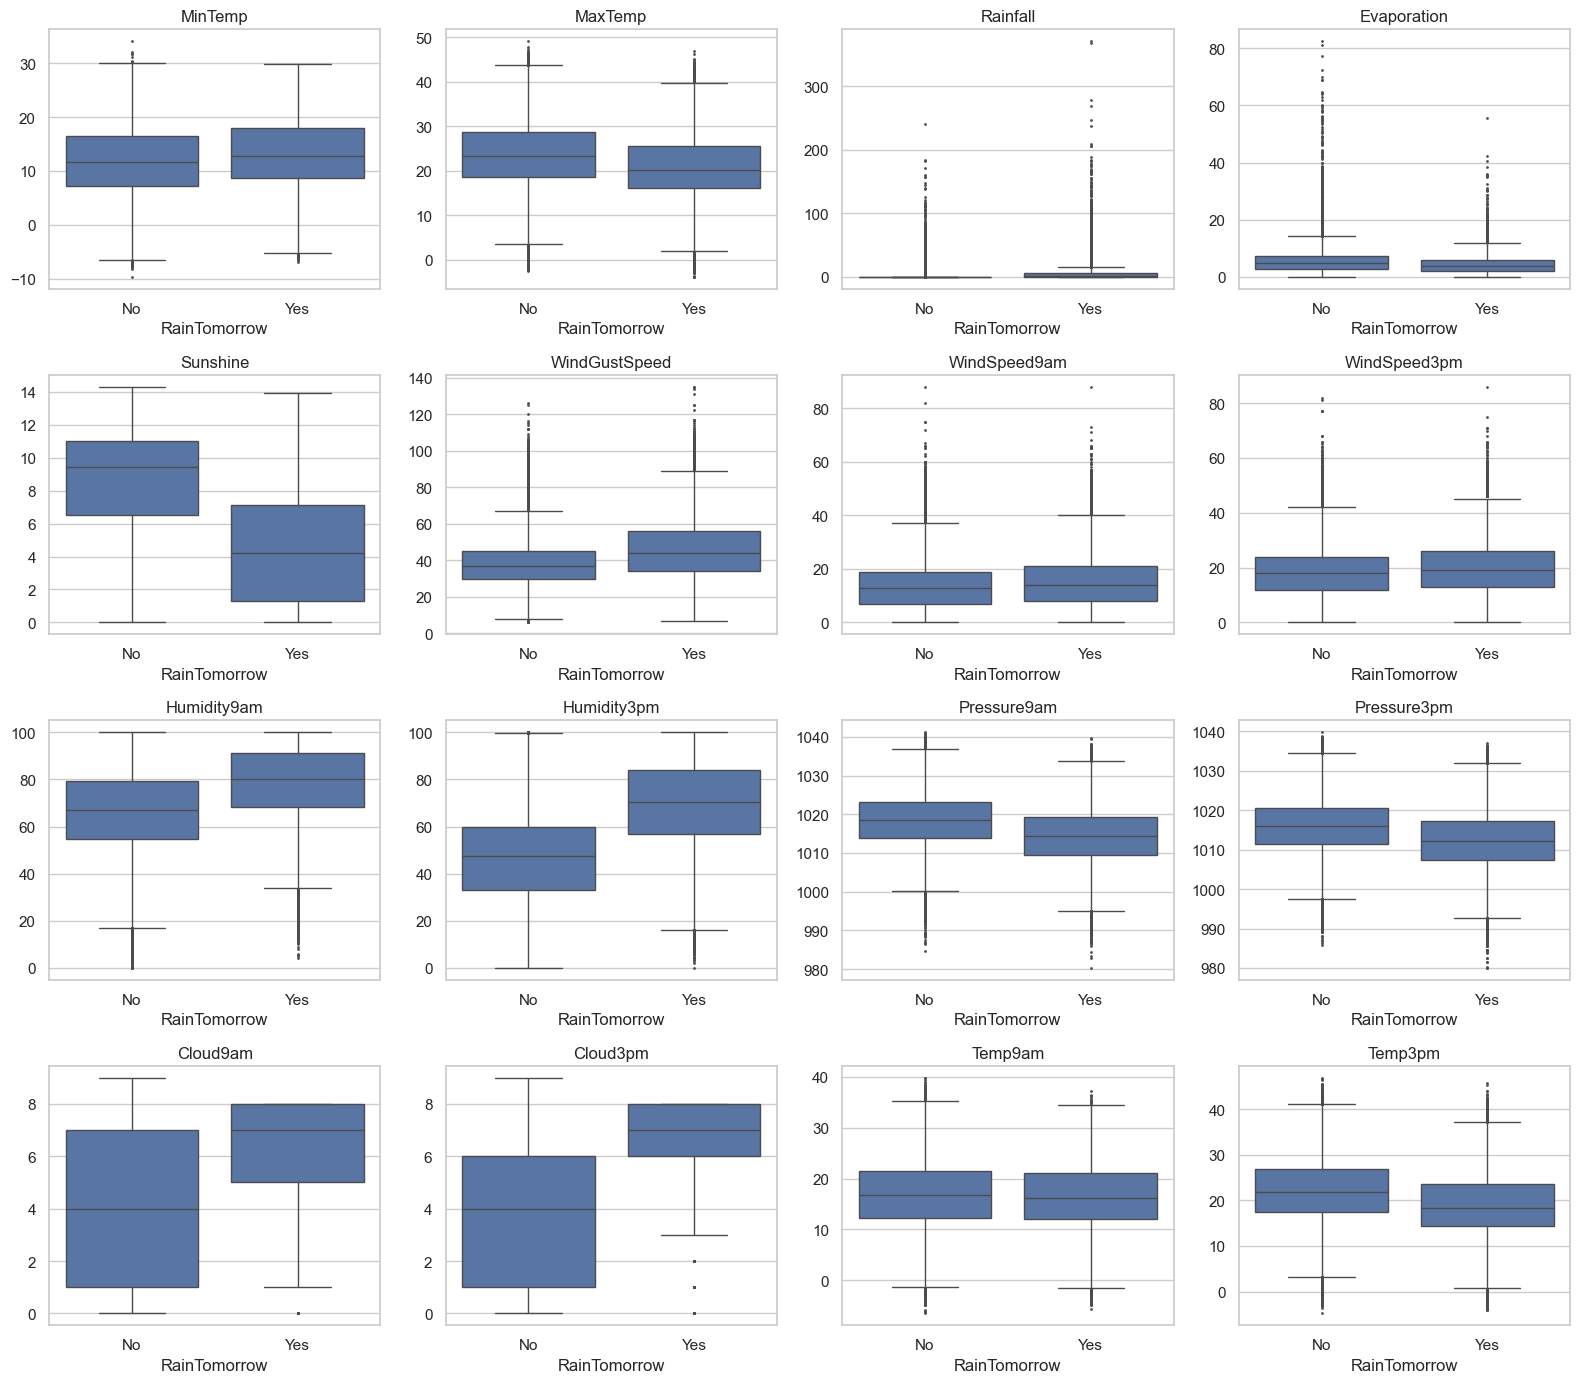

In [10]:
# Diagramas de caja de cada variable según si llueve o no al día siguiente
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
for ax, columna in zip(axes.ravel(), numericas):
    sns.boxplot(data=entrenamiento, x='RainTomorrow', y=columna, order=['No', 'Yes'],
                fliersize=1, ax=ax)
    ax.set(title=columna, xlabel='RainTomorrow', ylabel='')
plt.tight_layout()
plt.show()

Las cajas que más se separan entre los días seguidos de lluvia y el resto son las de `Humidity3pm`, `Sunshine`,
`Cloud9am` y `Cloud3pm`. Las temperaturas de la mañana casi no cambian. Hay muchos puntos fuera de los bigotes,
sobre todo en `Rainfall`, `Evaporation` y las velocidades del viento.

In [11]:
# Porcentaje de valores atípicos de cada variable con la regla del rango intercuartílico (IQR)
q1 = entrenamiento[numericas].quantile(0.25)
q3 = entrenamiento[numericas].quantile(0.75)
iqr = q3 - q1
fuera = (entrenamiento[numericas] < q1 - 1.5 * iqr) | (entrenamiento[numericas] > q3 + 1.5 * iqr)
(fuera.sum() / entrenamiento[numericas].notna().sum() * 100).sort_values(ascending=False).round(1)

Rainfall         18.0
Evaporation       2.6
WindGustSpeed     2.3
WindSpeed9am      1.4
WindSpeed3pm      1.2
Humidity9am       1.1
Pressure9am       0.8
Pressure3pm       0.7
Temp3pm           0.6
MaxTemp           0.4
Temp9am           0.2
MinTemp           0.0
Sunshine          0.0
Humidity3pm       0.0
Cloud9am          0.0
Cloud3pm          0.0
dtype: float64

Con la regla del rango intercuartílico (la del notebook de EDA de la cátedra), `Rainfall` tiene 18 % de valores
atípicos y el resto de las variables, menos de 3 %. `Rainfall` la miramos aparte, en los días con lluvia, que son
los de `Rainfall` mayor a 1 según la relación con `RainToday` de la sección 1.1.

Días con Rainfall = 0: 63.3%


count    23861.0
mean        10.4
std         15.8
min          1.1
50%          5.2
90%         23.6
99%         77.5
max        371.0
Name: Rainfall, dtype: float64

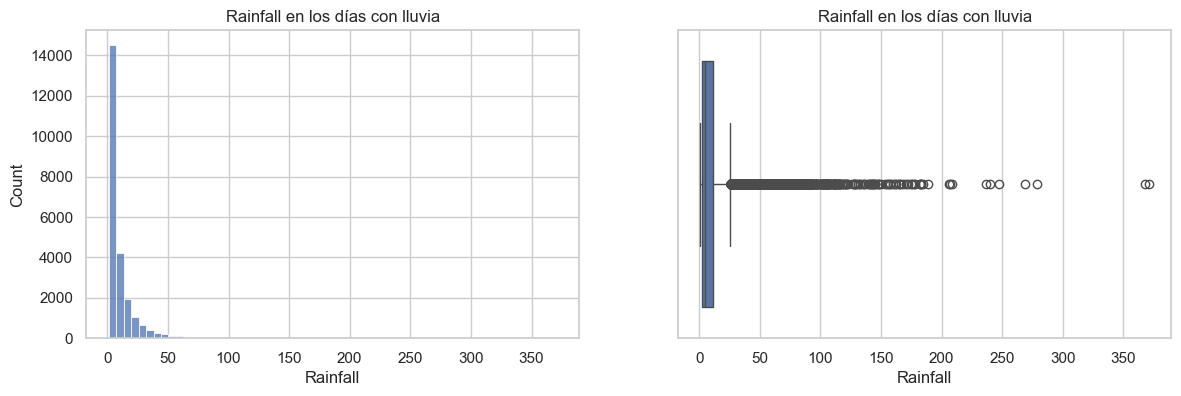

In [12]:
# Rainfall: proporción de días sin lluvia y distribución en los días con lluvia (Rainfall > 1)
lluvia_hoy = entrenamiento['Rainfall']
print(f'Días con Rainfall = 0: {(lluvia_hoy == 0).mean():.1%}')
display(lluvia_hoy[lluvia_hoy > 1].describe(percentiles=[0.5, 0.9, 0.99]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(lluvia_hoy[lluvia_hoy > 1], bins=60, ax=axes[0])
sns.boxplot(x=lluvia_hoy[lluvia_hoy > 1], ax=axes[1])
axes[0].set(title='Rainfall en los días con lluvia', xlabel='Rainfall')
axes[1].set(title='Rainfall en los días con lluvia', xlabel='Rainfall')
plt.show()

El 63.3 % de los días tiene `Rainfall` igual a 0, así que Q1 y Q3 quedan casi en 0 y la regla marca como atípico
a casi cualquier día con lluvia. En los días con lluvia la distribución es continua y con una cola larga: el 99 %
está por debajo de 77.5 y el máximo es 371. No parecen errores sino lluvias fuertes, y si las sacáramos, el modelo
no aprendería de esos días (apunte de la Unidad 0, sección 4.3).

Conservamos los atípicos y, como recomienda el apunte de la Unidad 0 en ese caso, aplicamos logaritmo a las
variables con asimetría mayor a 1 (sección 1.8).

### 1.4 Variables categóricas y fecha

In [13]:
# Categorías, la más frecuente y su cantidad de filas, para cada variable categórica
entrenamiento[categoricas].describe()

,Location,WindGustDir,WindDir9am,WindDir3pm,RainToday
count,107502,100103,99515,105314,106424
unique,49,16,16,16,2
top,Canberra,W,N,SE,No
freq,2696,7254,8577,8421,82563


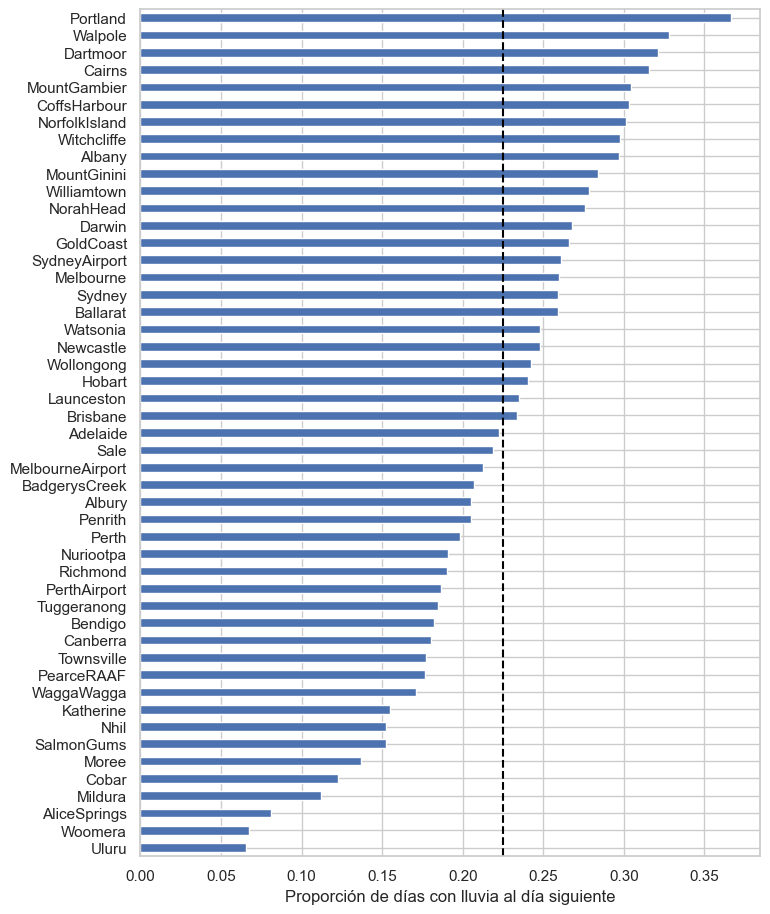

In [14]:
# Proporción de días seguidos de lluvia en cada ciudad (la línea es la proporción general)
lluvia = entrenamiento['RainTomorrow'] == 'Yes'

fig, ax = plt.subplots(figsize=(8, 11))
lluvia.groupby(entrenamiento['Location']).mean().sort_values().plot.barh(ax=ax)
ax.axvline(lluvia.mean(), color='black', linestyle='--')
ax.set(xlabel='Proporción de días con lluvia al día siguiente', ylabel='')
plt.show()

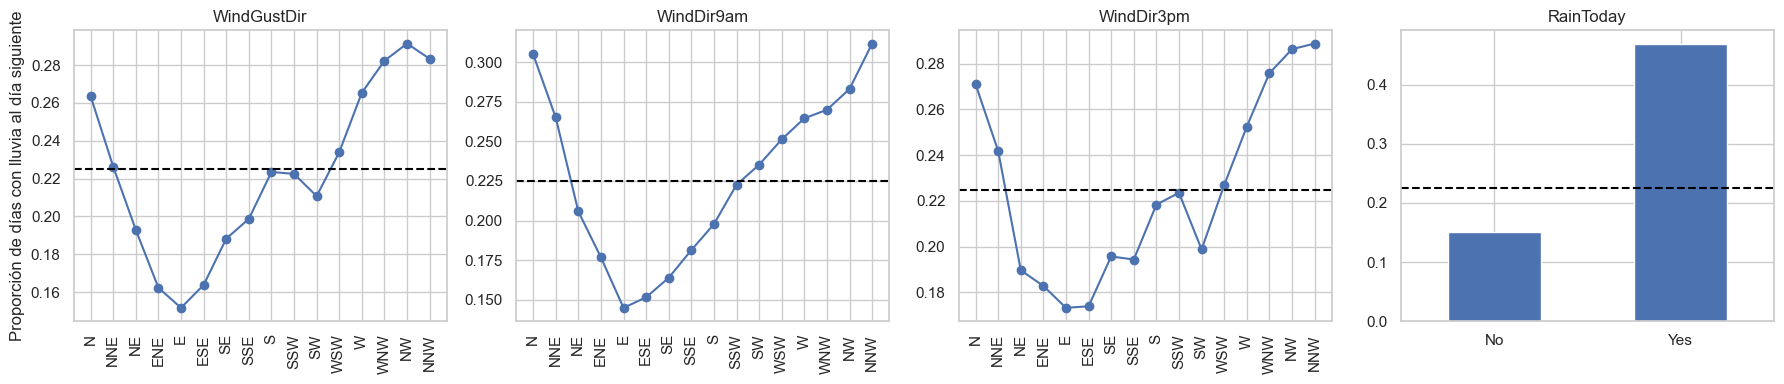

In [15]:
# Lo mismo para las direcciones del viento, en el orden de la brújula, y para RainToday
RUMBOS = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE', 'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, columna in zip(axes, ['WindGustDir', 'WindDir9am', 'WindDir3pm']):
    proporcion = lluvia.groupby(entrenamiento[columna]).mean().reindex(RUMBOS)
    ax.plot(RUMBOS, proporcion, marker='o')
    ax.set_title(columna)
    ax.tick_params(axis='x', rotation=90)
lluvia.groupby(entrenamiento['RainToday']).mean().plot.bar(ax=axes[3], rot=0)
axes[3].set(title='RainToday', xlabel='')
for ax in axes:
    ax.axhline(lluvia.mean(), color='black', linestyle='--')
axes[0].set_ylabel('Proporción de días con lluvia al día siguiente')
plt.tight_layout()
plt.show()

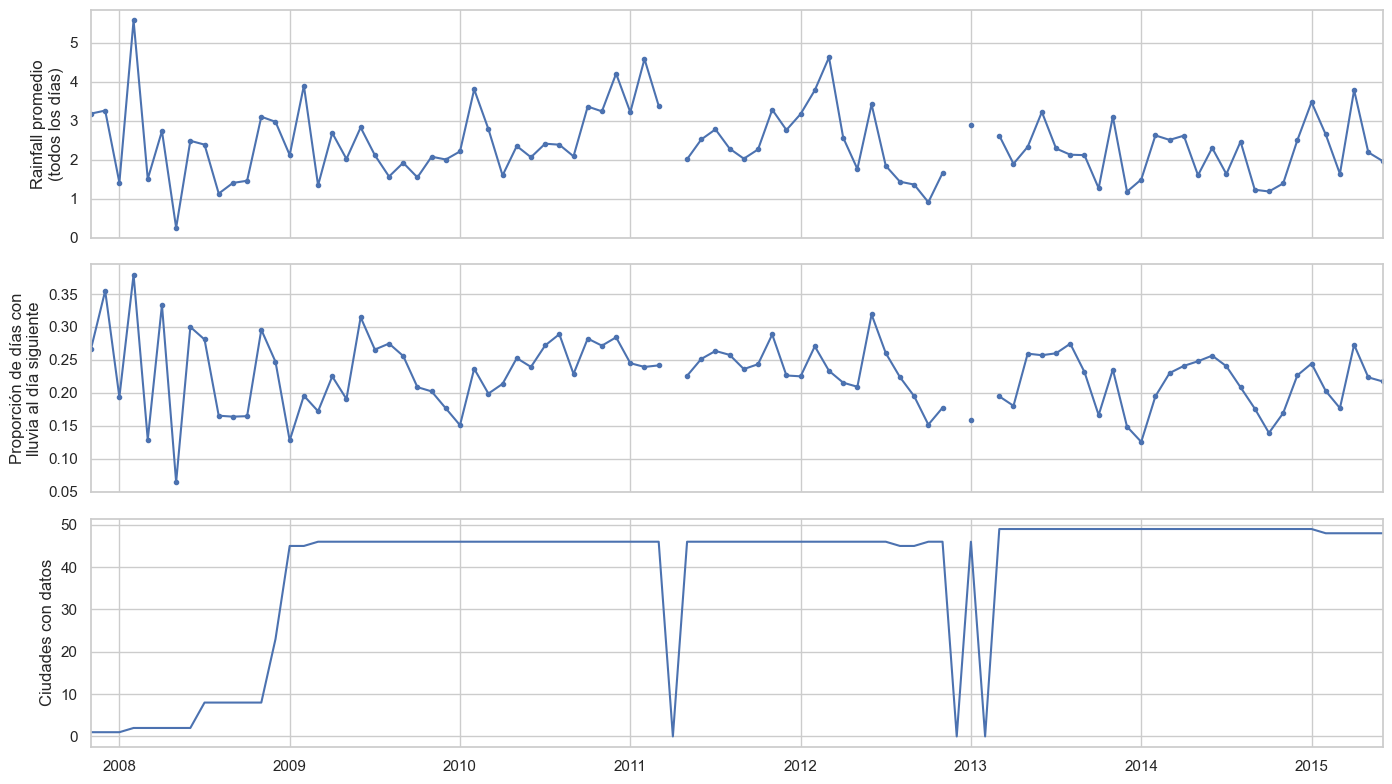

Meses sin ninguna ciudad con datos: ['2011-04', '2012-12', '2013-02']


In [16]:
# Rainfall promedio, proporción de días seguidos de lluvia y ciudades con datos, mes a mes
por_mes = entrenamiento.assign(lluvia=lluvia).resample('MS', on='Date')
ciudades_por_mes = por_mes['Location'].nunique()

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
por_mes['Rainfall'].mean().plot(ax=axes[0], marker='.')
por_mes['lluvia'].mean().plot(ax=axes[1], marker='.')
ciudades_por_mes.plot(ax=axes[2])
axes[0].set_ylabel('Rainfall promedio\n(todos los días)')
axes[1].set_ylabel('Proporción de días con\nlluvia al día siguiente')
axes[2].set(ylabel='Ciudades con datos', xlabel='')
plt.tight_layout()
plt.show()
print('Meses sin ninguna ciudad con datos:', [f'{mes:%Y-%m}' for mes in ciudades_por_mes[ciudades_por_mes == 0].index])

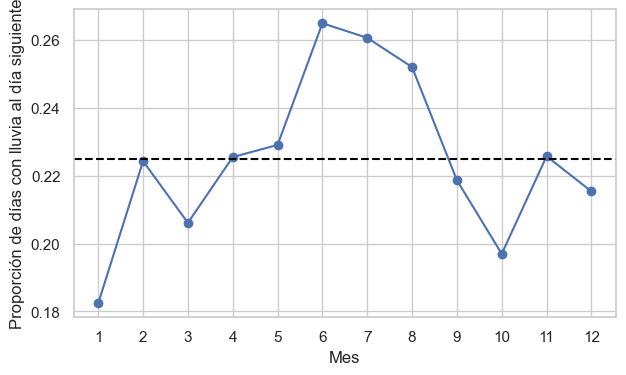

In [17]:
# Proporción de días seguidos de lluvia según el mes del año
ax = lluvia.groupby(entrenamiento['Date'].dt.month).mean().plot(marker='o', figsize=(7, 4))
ax.axhline(lluvia.mean(), color='black', linestyle='--')
ax.set(xlabel='Mes', xticks=range(1, 13), ylabel='Proporción de días con lluvia al día siguiente')
plt.show()

- `Location`: la proporción de días seguidos de lluvia va de menos del 10 % a más del 35 % según la ciudad.
- Direcciones del viento: en el orden de la brújula, la proporción cambia de forma continua, con un máximo entre NW
  y N y un mínimo cerca de E. Los rumbos vecinos se parecen, incluido el último (NNW) con el primero (N).
- `RainToday`: después de un día con lluvia, llueve al día siguiente en cerca del 47 % de los casos, contra el 15 %
  después de un día sin lluvia.
- A lo largo del tiempo, el `Rainfall` promedio y la proporción de días seguidos de lluvia suben y bajan juntas, sin
  una tendencia. Hay tres meses sin ningún dato (enero de 2013 queda como un punto aislado entre dos de ellos), y
  hasta fines de 2008 hay menos de 10 ciudades, por eso las curvas saltan tanto al principio.
- Mes del año: la proporción sube a mitad de año (junio a agosto, alrededor del 26 %) y es mínima en enero (18 %).

Todas se relacionan con la lluvia, así que las usamos. Las direcciones y el mes son cíclicos, y para ellos usamos la
codificación cíclica del apunte de la Unidad 0 (sección 5.3.9): el seno y el coseno del valor. Así los valores
vecinos quedan cerca (NNW y N, diciembre y enero), con dos columnas en lugar de las 15 u 11 del one-hot. El año no
lo usamos, porque el modelo siempre va a predecir años que no vio. `Location` y `RainToday` van con one-hot
(sección 1.8).

### 1.5 Datos faltantes

In [18]:
# Porcentaje de faltantes de cada variable
faltantes = entrenamiento.isna().mean().sort_values(ascending=False) * 100
faltantes[faltantes > 0].round(1)

Sunshine         42.0
Evaporation      38.4
Cloud3pm         37.2
Cloud9am         36.3
Pressure9am       9.6
Pressure3pm       9.5
WindDir9am        7.4
WindGustDir       6.9
WindGustSpeed     6.8
WindDir3pm        2.0
Humidity9am       1.3
Humidity3pm       1.2
WindSpeed3pm      1.1
WindSpeed9am      1.1
RainToday         1.0
Rainfall          1.0
Temp9am           0.7
Temp3pm           0.6
MinTemp           0.4
MaxTemp           0.2
dtype: float64

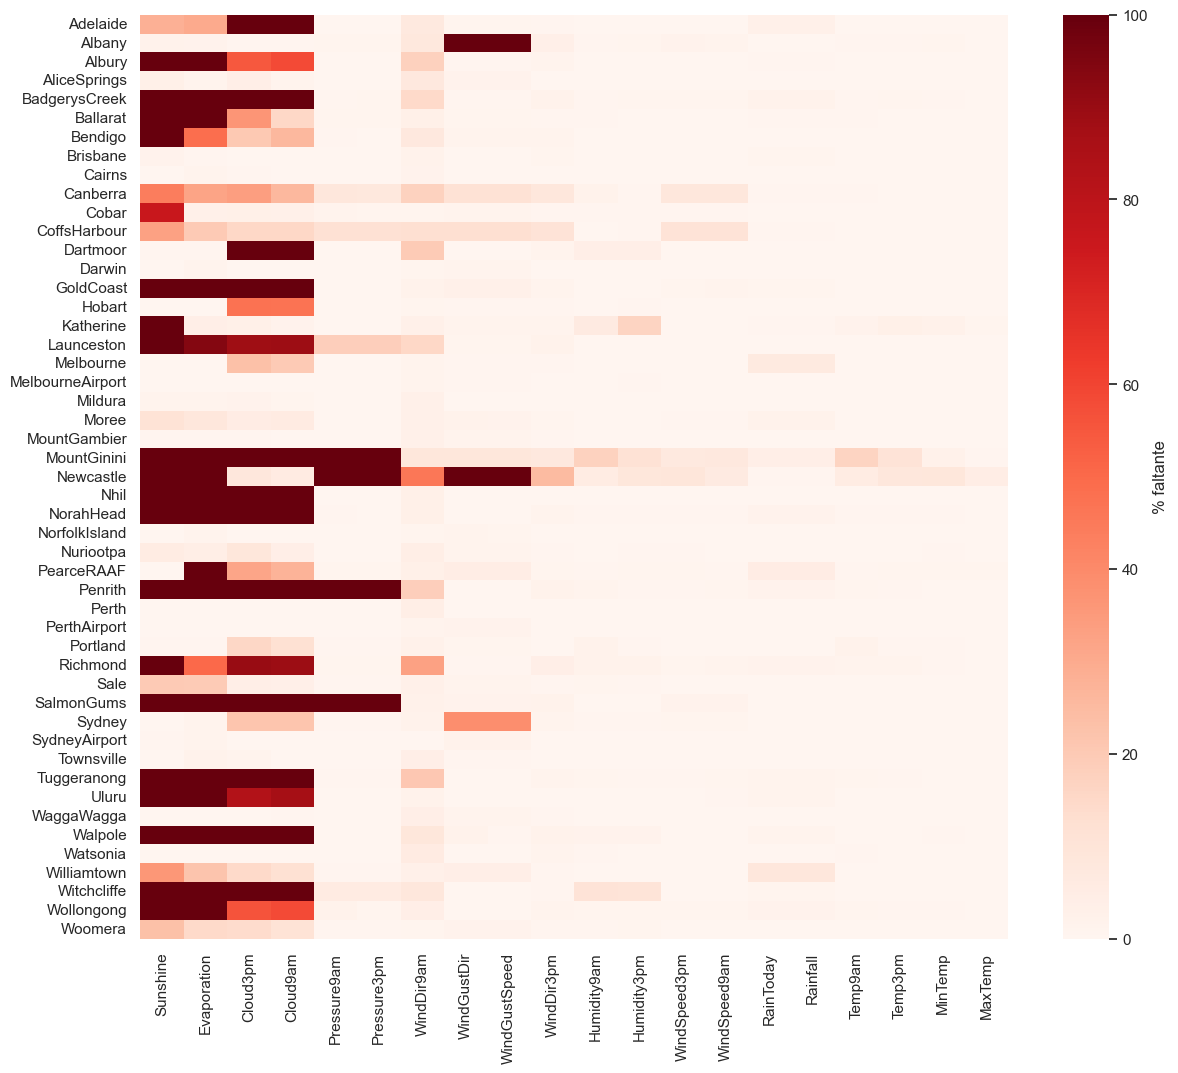

In [19]:
# Porcentaje de faltantes de cada variable en cada ciudad
con_faltantes = faltantes[faltantes > 0].index
plt.figure(figsize=(14, 12))
sns.heatmap(entrenamiento[con_faltantes].isna().groupby(entrenamiento['Location']).mean() * 100,
            cmap='Reds', cbar_kws={'label': '% faltante'})
plt.xlabel('')
plt.ylabel('')
plt.show()

In [20]:
# Parte de los faltantes de cada variable numérica que es de ciudades sin ningún dato de esa variable
falta = entrenamiento[numericas].isna()
ciudad_sin_datos = falta.groupby(entrenamiento['Location']).transform('all')
origen = pd.DataFrame({'Faltantes': falta.sum(),
                       '% en ciudades sin ningún dato': (falta & ciudad_sin_datos).sum() / falta.sum() * 100})
display(origen[origen['Faltantes'] > 0].sort_values('Faltantes', ascending=False).round(1))
print(f'En total: {(falta & ciudad_sin_datos).sum().sum() / falta.sum().sum():.1%} de los faltantes numéricos')

,Faltantes,% en ciudades sin ningún dato
Sunshine,45182,85.2
Evaporation,41281,79.6
Cloud3pm,40001,63.7
Cloud9am,38979,65.4
Pressure9am,10285,86.8
Pressure3pm,10249,87.1
WindGustSpeed,7356,62.0
Humidity9am,1390,0.0
Humidity3pm,1322,0.0
WindSpeed3pm,1183,0.0


En total: 71.8% de los faltantes numéricos


`Sunshine`, `Evaporation`, `Cloud3pm` y `Cloud9am` tienen entre 36 % y 42 % de faltantes; el resto, menos de 10 %. El
mapa muestra que los faltantes dependen de la ciudad: varias ciudades no tienen ningún dato de alguna variable, y
otras casi no tienen faltantes. No faltan completamente al azar, sino según una variable observada, la ciudad (MAR,
en los términos del apunte de la Unidad 0).

La tabla lo cuantifica: el 71.8 % de los faltantes numéricos es de ciudades que nunca miden esa variable (85.2 % en
`Sunshine` y 87 % en las presiones). Una imputación simple, como la mediana, les pone siempre el mismo valor. KNN,
en cambio, completa cada fila con los días más parecidos, que pueden ser de otras ciudades. Lo probamos ocultando
las cuatro variables con más faltantes en ciudades que sí las miden:

In [21]:
# Prueba: en las 8 ciudades con más filas completas, ocultamos las cuatro variables con más faltantes y las
# imputamos con la mediana y con KNN (k=5), a partir de las otras ciudades. Las variables van estandarizadas,
# así el error queda en desvíos estándar y KNN mide distancias con todas en la misma escala
cuatro = faltantes.index[:4].tolist()
media, desvio = entrenamiento[numericas].mean(), entrenamiento[numericas].std()
estandarizadas = (entrenamiento[numericas] - media) / desvio
ciudad = entrenamiento['Location']
completas = estandarizadas[cuatro].notna().all(axis=1)

nubes = ['Cloud3pm', 'Cloud9am']
errores = {'Mediana': [], 'KNN': [], 'KNN redondeado': []}
for c in ciudad[completas].value_counts().index[:8]:
    reales = estandarizadas[completas & (ciudad == c)].sample(500, random_state=SEMILLA)
    ocultas = reales.copy()
    ocultas[cuatro] = np.nan
    otras = estandarizadas[ciudad != c].sample(20000, random_state=SEMILLA)  # una muestra, para que no tarde
    imputadas = pd.DataFrame(KNNImputer(n_neighbors=5).fit(otras).transform(ocultas),
                             columns=numericas, index=reales.index)
    errores['KNN'].append(((imputadas[cuatro] - reales[cuatro]) ** 2).mean() ** 0.5)
    errores['Mediana'].append(((otras[cuatro].median() - reales[cuatro]) ** 2).mean() ** 0.5)

    # La nubosidad toma valores enteros: probamos también redondear lo que imputa KNN
    redondeadas = (imputadas[nubes] * desvio[nubes] + media[nubes]).round()
    redondeadas = (redondeadas - media[nubes]) / desvio[nubes]
    errores['KNN redondeado'].append(((redondeadas - reales[nubes]) ** 2).mean() ** 0.5)

# Raíz del error cuadrático medio, promedio de las 8 ciudades (el redondeo solo aplica a la nubosidad)
pd.DataFrame({nombre: pd.concat(lista, axis=1).mean(axis=1) for nombre, lista in errores.items()}).T[cuatro].round(3)

,Sunshine,Evaporation,Cloud3pm,Cloud9am
Mediana,1.026,0.784,1.002,0.997
KNN,0.776,0.586,0.878,0.845
KNN redondeado,NaN,NaN,0.885,0.854


KNN se equivoca entre 12 % y 25 % menos que la mediana en las cuatro variables (en `Sunshine`, 0.776 desvíos
contra 1.026). En la nubosidad, que toma valores enteros, KNN deja decimales, porque promedia 5 vecinos. Redondearlos
empeora apenas el error (0.885 y 0.854 contra 0.878 y 0.845), así que los dejamos: para la regresión logística la
nubosidad es una variable numérica, y un 4.6 se lee como "entre 4 y 5".

Decisiones:

- Numéricas: `KNNImputer` con 5 vecinos. El apunte de la Unidad 0 (sección 3.2.3) dice que suele dar mejores
  resultados y que conviene cuando la imputación simple no alcanza, como en este caso. Como usa distancias, va
  después del escalado, y se ajusta solo con entrenamiento (sección 1.8).
- Las cuatro variables con más faltantes se conservan: en los diagramas de caja están entre las que más separan las
  clases, y en su notebook de imputación la cátedra descarta una variable recién cuando le falta el 77 %.
- `RainToday`: la moda. Las direcciones del viento se imputan como numéricas, después de pasarlas a seno y coseno.

### 1.6 Balance de clases

In [22]:
# Cantidad de días con y sin lluvia al día siguiente
conteo = entrenamiento['RainTomorrow'].value_counts()
print(conteo)
print(f"Días con lluvia: {conteo['Yes'] / conteo.sum():.1%}")
print(f"Relación de desbalance (No / Yes): {conteo['No'] / conteo['Yes']:.1f}")

RainTomorrow
No     83320
Yes    24182
Name: count, dtype: int64
Días con lluvia: 22.5%
Relación de desbalance (No / Yes): 3.4


El 22.5 % de los días está seguido de un día de lluvia: hay 3.4 días sin lluvia por cada uno con lluvia. La clase
minoritaria tiene el 29 % de las observaciones de la mayoritaria, así que, con el criterio del notebook de EDA de la
cátedra (entre 20 % y 40 %), el dataset está moderadamente desbalanceado.

Importa por dos motivos: un modelo que diga siempre "no llueve" acertaría el 77.5 % de las veces sin aprender nada,
y al minimizar el error total el modelo tiende a favorecer a la clase mayoritaria (clase 9). Por eso en el ítem 2
usamos `class_weight='balanced'` y métricas de la clase "llueve".

### 1.7 Matriz de correlación

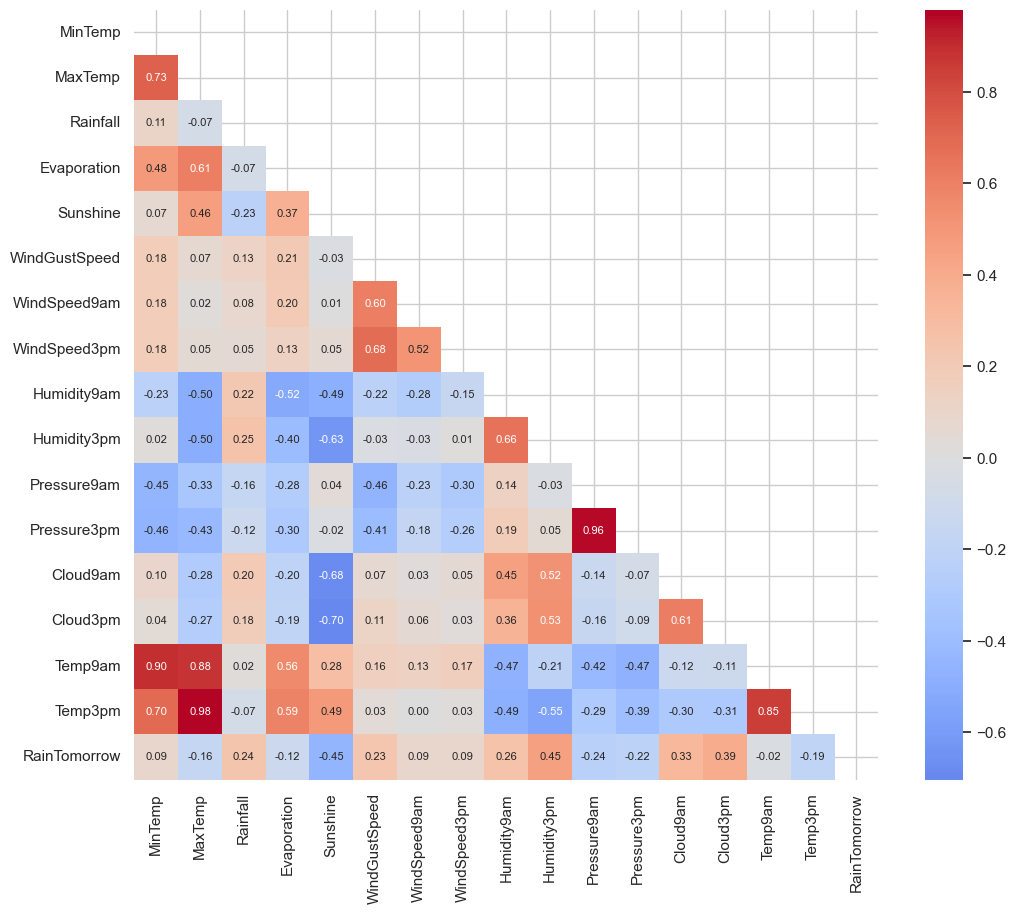

In [23]:
# Correlación entre las variables numéricas y con la variable objetivo (0/1)
correlacion = entrenamiento[numericas].assign(RainTomorrow=y_train).corr()
triangulo_superior = np.triu(np.ones(correlacion.shape, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(correlacion, mask=triangulo_superior, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, annot_kws={'size': 8})
plt.show()

In [24]:
# Pares de variables con correlación de 0.85 o más (umbral del notebook de EDA de la cátedra)
for i, a in enumerate(numericas):
    for b in numericas[i + 1:]:
        if abs(correlacion.loc[a, b]) >= 0.85:
            print(f'{a} y {b}: {correlacion.loc[a, b]:.2f}')

MinTemp y Temp9am: 0.90
MaxTemp y Temp9am: 0.88
MaxTemp y Temp3pm: 0.98
Pressure9am y Pressure3pm: 0.96
Temp9am y Temp3pm: 0.85


Con la variable objetivo (última fila), las correlaciones más fuertes son las de `Humidity3pm` (0.45), `Sunshine`
(−0.45), `Cloud3pm` (0.39) y `Cloud9am` (0.33). Hay cinco pares con correlación de 0.85 o más, todos entre
temperaturas o entre presiones.

Los dejamos: sacar una de ellas puede hacer perder la información que no comparte con la otra (apunte de la Unidad
0, sección 5.4, y notebook `correlacion.ipynb`), y la regularización L2 de la regresión logística reparte el peso
entre variables correlacionadas (clase 5).

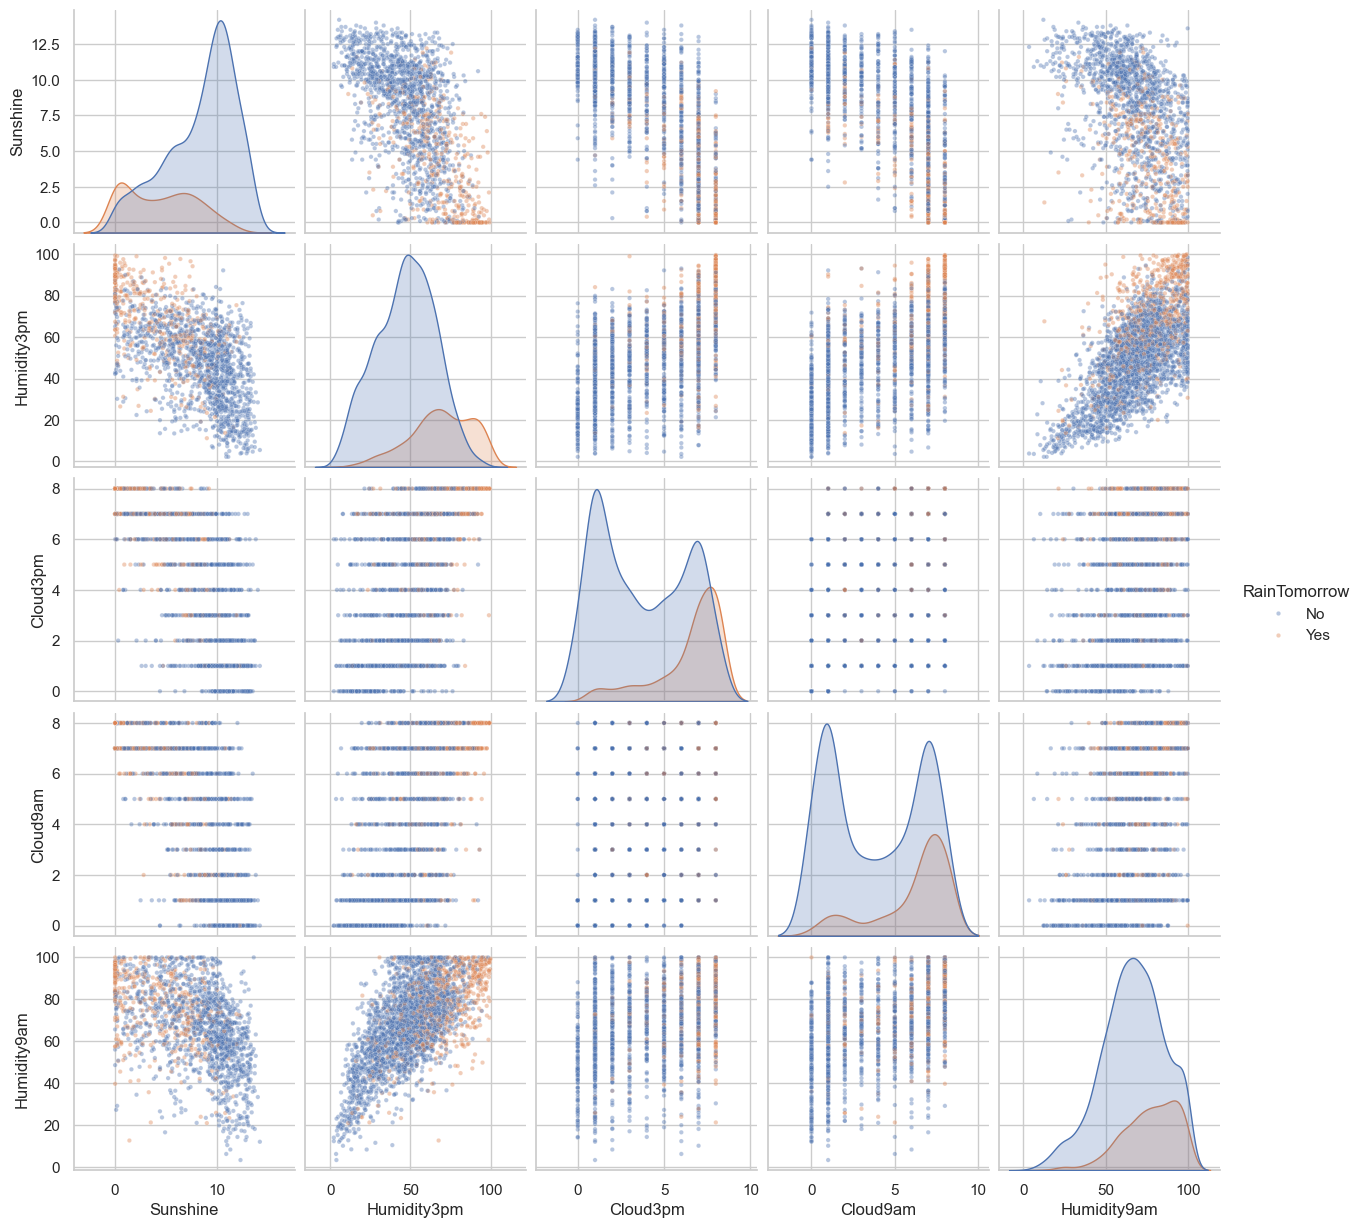

In [25]:
# Pairplot de las cinco variables más correlacionadas con la variable objetivo, sobre una muestra
mas_correlacionadas = correlacion['RainTomorrow'].drop('RainTomorrow').abs().nlargest(5).index.tolist()
muestra = entrenamiento.sample(3000, random_state=SEMILLA)
sns.pairplot(muestra, vars=mas_correlacionadas, hue='RainTomorrow', hue_order=['No', 'Yes'],
             plot_kws={'alpha': 0.4, 's': 10})
plt.show()

En las cinco variables más correlacionadas con la variable objetivo, los días seguidos de lluvia (naranja) se
concentran con poco sol, humedad alta y mucha nubosidad. Pero las clases se superponen en todos los pares: ninguna
combinación de dos variables las separa.

### 1.8 Preparación de los datos: codificación, imputación y escalado

Aplicamos las decisiones anteriores, en este orden:

1. Codificación cíclica de las direcciones del viento y del mes.
2. Logaritmo de las variables con asimetría mayor a 1.
3. Escalado e imputación con KNN de las numéricas, y moda y one-hot de las categóricas.

Los pasos 1 y 2 son fórmulas fijas que no aprenden nada de los datos, así que se aplican igual a los tres
conjuntos. El paso 3 se ajusta solo con entrenamiento.

In [26]:
# Codificación cíclica: seno y coseno de 2π·valor/n (N = 1, ..., NNW = 16 y enero = 1, ..., diciembre = 12)
direcciones = ['WindGustDir', 'WindDir9am', 'WindDir3pm']
numero_rumbo = {rumbo: i + 1 for i, rumbo in enumerate(RUMBOS)}

for X, conjunto in [(X_train, entrenamiento), (X_val, validacion), (X_test, prueba)]:
    for columna in direcciones:
        valor = X[columna].map(numero_rumbo)
        X[columna + '_sin'] = np.sin(2 * np.pi * valor / 16)
        X[columna + '_cos'] = np.cos(2 * np.pi * valor / 16)
    mes = conjunto['Date'].dt.month
    X['Mes_sin'] = np.sin(2 * np.pi * mes / 12)
    X['Mes_cos'] = np.cos(2 * np.pi * mes / 12)
    X.drop(columns=direcciones, inplace=True)

# Las columnas nuevas son numéricas; como categóricas quedan Location y RainToday
numericas = numericas + ['WindGustDir_sin', 'WindGustDir_cos', 'WindDir9am_sin', 'WindDir9am_cos',
                         'WindDir3pm_sin', 'WindDir3pm_cos', 'Mes_sin', 'Mes_cos']
categoricas = ['Location', 'RainToday']
X_train[numericas[-8:]].describe().round(2)

,WindGustDir_sin,WindGustDir_cos,WindDir9am_sin,WindDir9am_cos,WindDir3pm_sin,WindDir3pm_cos,Mes_sin,Mes_cos
count,100103.00,100103.00,99515.00,99515.00,105314.00,105314.00,107502.00,107502.00
mean,-0.04,-0.04,0.02,0.00,-0.03,-0.04,0.02,-0.02
std,0.71,0.70,0.69,0.72,0.70,0.71,0.70,0.71
min,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00
25%,-0.71,-0.71,-0.71,-0.71,-0.71,-0.71,-0.50,-0.87
50%,-0.00,-0.00,0.00,0.00,-0.00,-0.00,0.00,-0.00
75%,0.71,0.71,0.71,0.71,0.71,0.71,0.50,0.50
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


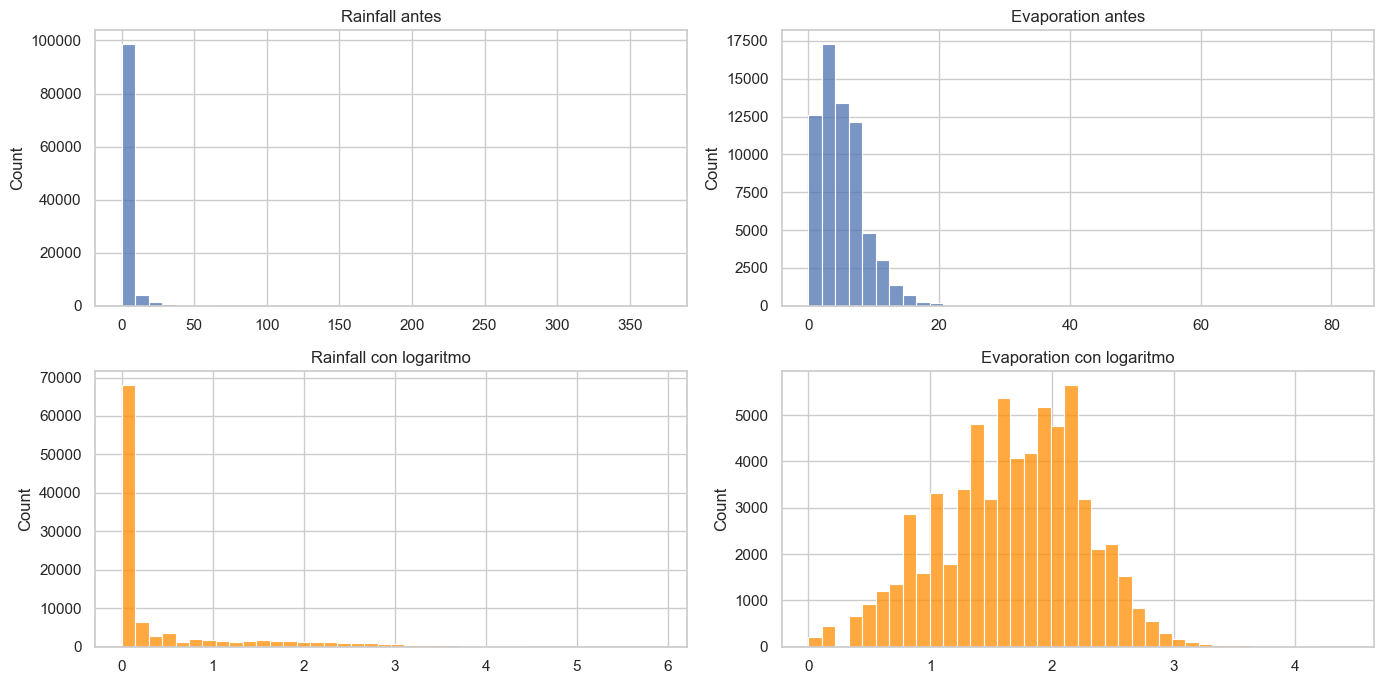

,Asimetría antes,Asimetría después,Máximo antes,Máximo después
Rainfall,9.99,2.04,371.0,5.92
Evaporation,3.19,-0.20,82.4,4.42


In [27]:
# Logaritmo, log(x + 1), de las variables con asimetría mayor a 1 (tabla de la sección 1.3)
asimetricas = resumen.index[resumen['Asimetría'] > 1].tolist()
antes = X_train[asimetricas].copy()
for X in [X_train, X_val, X_test]:
    X[asimetricas] = np.log1p(X[asimetricas])

fig, axes = plt.subplots(2, len(asimetricas), figsize=(14, 7))
for j, columna in enumerate(asimetricas):
    sns.histplot(antes[columna], bins=40, ax=axes[0, j])
    sns.histplot(X_train[columna], bins=40, color='darkorange', ax=axes[1, j])
    axes[0, j].set(title=f'{columna} antes', xlabel='')
    axes[1, j].set(title=f'{columna} con logaritmo', xlabel='')
plt.tight_layout()
plt.show()

pd.DataFrame({'Asimetría antes': antes.skew(), 'Asimetría después': X_train[asimetricas].skew(),
              'Máximo antes': antes.max(), 'Máximo después': X_train[asimetricas].max()}).round(2)

Con el logaritmo, la asimetría de `Rainfall` baja de 9.99 a 2.04 y la de `Evaporation`, de 3.19 a −0.20. Los
valores extremos quedan mucho más cerca del resto: el máximo de `Rainfall` pasa de 371 a 5.92.

In [28]:
# Numéricas: escalado y después KNN, que usa distancias. Categóricas: moda y one-hot
preprocesador = ColumnTransformer([
    ('num', Pipeline([('escalador', StandardScaler()),
                      ('imputador', KNNImputer(n_neighbors=5))]), numericas),
    ('cat', Pipeline([('imputador', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(drop='if_binary', handle_unknown='ignore',
                                               sparse_output=False))]), categoricas),
])
preprocesador.set_output(transform='pandas')

# Se ajusta solo con entrenamiento; validación y prueba se transforman con lo aprendido ahí.
# Tarda varios minutos (KNN compara cada fila con faltantes con todas las de entrenamiento), así que la primera
# vez se guarda el resultado y después se carga. Si se cambia la preparación, hay que borrar ese archivo
archivo = 'data/preprocesado.joblib'
if os.path.exists(archivo):
    preprocesador, X_train_prep, X_val_prep, X_test_prep = joblib.load(archivo)
    print('Datos preparados cargados de', archivo)
else:
    X_train_prep = preprocesador.fit_transform(X_train)
    X_val_prep = preprocesador.transform(X_val)
    X_test_prep = preprocesador.transform(X_test)
    joblib.dump((preprocesador, X_train_prep, X_val_prep, X_test_prep), archivo)
    print('Datos preparados guardados en', archivo)

X_train_prep.info(verbose=True, show_counts=True)

Datos preparados cargados de data/preprocesado.joblib
<class 'pandas.core.frame.DataFrame'>
Index: 107502 entries, 45573 to 123065
Data columns (total 74 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   num__MinTemp                    107502 non-null  float64
 1   num__MaxTemp                    107502 non-null  float64
 2   num__Rainfall                   107502 non-null  float64
 3   num__Evaporation                107502 non-null  float64
 4   num__Sunshine                   107502 non-null  float64
 5   num__WindGustSpeed              107502 non-null  float64
 6   num__WindSpeed9am               107502 non-null  float64
 7   num__WindSpeed3pm               107502 non-null  float64
 8   num__Humidity9am                107502 non-null  float64
 9   num__Humidity3pm                107502 non-null  float64
 10  num__Pressure9am                107502 non-null  float64
 11  num__Pressure3pm         

In [29]:
# Faltantes que quedan en cada conjunto, y media y desvío de las numéricas ya escaladas
print('Faltantes:', X_train_prep.isna().sum().sum(), X_val_prep.isna().sum().sum(), X_test_prep.isna().sum().sum())
X_train_prep.filter(like='num__').describe().round(2)

Faltantes: 0 0 0


,num__MinTemp,num__MaxTemp,num__Rainfall,num__Evaporation,num__Sunshine,num__WindGustSpeed,num__WindSpeed9am,num__WindSpeed3pm,num__Humidity9am,num__Humidity3pm,...,num__Temp9am,num__Temp3pm,num__WindGustDir_sin,num__WindGustDir_cos,num__WindDir9am_sin,num__WindDir9am_cos,num__WindDir3pm_sin,num__WindDir3pm_cos,num__Mes_sin,num__Mes_cos
count,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,...,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00,107502.00
mean,-0.00,-0.00,-0.00,-0.05,-0.00,-0.02,-0.00,-0.00,0.00,0.00,...,-0.00,-0.00,0.00,-0.00,0.00,0.01,0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,0.93,0.92,0.98,1.00,1.00,1.00,1.00,...,1.00,1.00,0.98,0.98,0.97,0.97,0.99,0.99,1.00,1.00
min,-3.42,-3.84,-0.54,-2.82,-2.01,-2.49,-1.57,-2.09,-3.62,-2.48,...,-3.63,-3.84,-1.36,-1.36,-1.47,-1.39,-1.38,-1.35,-1.44,-1.38
25%,-0.71,-0.74,-0.54,-0.71,-0.66,-0.67,-0.79,-0.75,-0.62,-0.71,...,-0.73,-0.73,-0.95,-0.95,-1.05,-0.98,-0.96,-0.94,-0.73,-1.19
50%,-0.03,-0.08,-0.54,-0.01,0.13,-0.16,-0.12,-0.08,0.06,0.02,...,-0.05,-0.09,0.05,0.06,-0.03,-0.00,0.05,0.06,-0.02,0.03
75%,0.72,0.70,0.11,0.64,0.74,0.50,0.55,0.59,0.75,0.68,...,0.70,0.68,1.05,1.06,0.99,0.98,1.05,1.06,0.69,0.73
max,3.45,3.70,5.97,4.63,1.77,6.92,8.22,7.54,1.64,2.33,...,3.56,3.68,1.46,1.48,1.42,1.38,1.47,1.47,1.40,1.44


El `ColumnTransformer` aplica a cada lista de columnas sus propios pasos: a las de `numericas` (prefijo `num__`),
`StandardScaler` y después `KNNImputer`; a las de `categoricas` (prefijo `cat__`), la moda y el one-hot.

- `StandardScaler` deja cada numérica con media 0 y desvío 1, calculados en entrenamiento. Escalamos porque las
  escalas son muy distintas, porque KNN mide distancias y porque la regularización castiga el tamaño de los
  coeficientes (apunte de la Unidad 0, sección 5.1.1). La media y el desvío no quedan exactamente en 0 y 1 en las
  variables con faltantes, porque los valores imputados se agregan después de escalar.
- One-hot: `Location` conserva sus 49 columnas, porque en uso real puede aparecer una ciudad nueva, que queda con
  todas en 0 (`handle_unknown='ignore'`; apunte de la Unidad 0, secciones 5.3.2 y 5.3.3). `RainToday`, que tiene
  dos categorías, queda en una sola columna 0/1 (`drop='if_binary'`).

Quedan 74 columnas (24 numéricas, 49 de `Location` y 1 de `RainToday`), sin faltantes en ninguno de los tres
conjuntos.

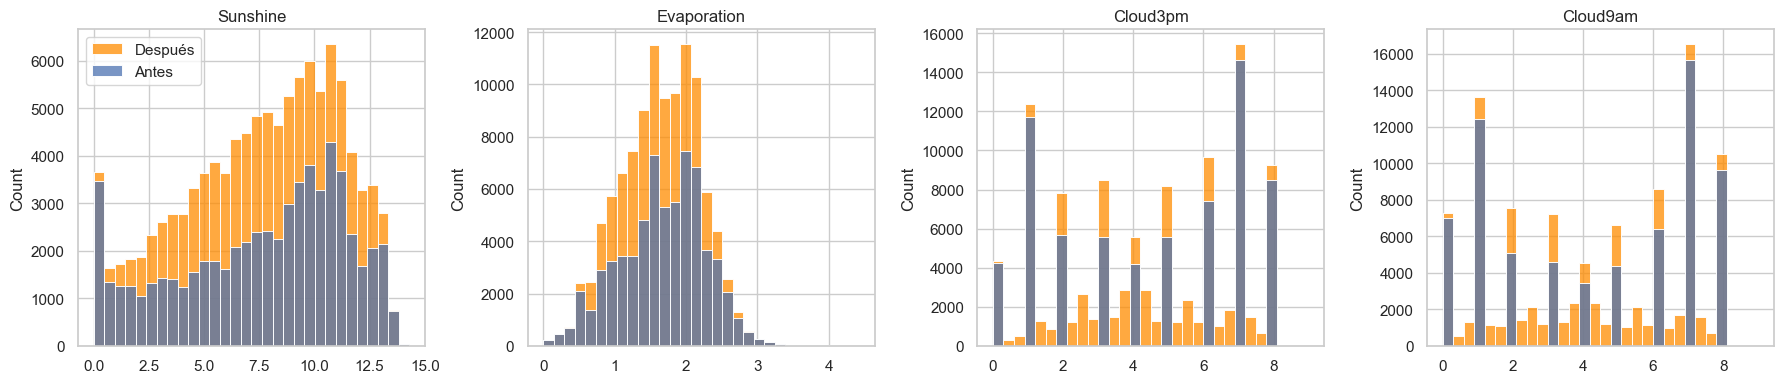

In [30]:
# Distribución antes y después de imputar, en las cuatro variables con más faltantes.
# Para verlas en sus unidades, deshacemos el escalado de los datos ya imputados
escalador = preprocesador.named_transformers_['num']['escalador']
imputadas = pd.DataFrame(escalador.inverse_transform(X_train_prep.filter(like='num__')),
                         columns=numericas, index=X_train.index)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, columna in zip(axes, cuatro):
    sns.histplot(imputadas[columna], bins=30, color='darkorange', label='Después', ax=ax)
    sns.histplot(X_train[columna], bins=30, label='Antes', ax=ax)
    ax.set(title=columna, xlabel='')
axes[0].legend()
plt.tight_layout()
plt.show()

KNN completa cada faltante con el promedio de los 5 días más parecidos de entrenamiento, así que los valores
imputados siguen la forma de cada distribución en lugar de acumularse en un solo valor. En la nubosidad aparecen
valores intermedios entre los enteros, que son esos promedios (sección 1.5).

## 2. Regresión logística

Usamos `class_weight='balanced'`, que pesa los errores de cada clase según la inversa de su frecuencia: con el
desbalance de la sección 1.6, equivocarse en un día de lluvia cuesta 3.4 veces más que en uno sin lluvia (clase 9).
El modelo se entrena con los datos ya preparados en el ítem 1, así el preprocesamiento no se vuelve a ajustar.

In [31]:
# La regresión logística se entrena con los datos ya preparados en el ítem 1
modelo = LogisticRegression(class_weight='balanced')
modelo.fit(X_train_prep, y_train)

# Probabilidad de lluvia que da el modelo en validación y en prueba
prob_val = modelo.predict_proba(X_val_prep)[:, 1]
prob_test = modelo.predict_proba(X_test_prep)[:, 1]

### 2.1 Métricas y matrices de confusión

La clase positiva es "llueve" (1).

- Accuracy: proporción de aciertos. Con clases desbalanceadas engaña (sección 1.6).
- Precisión: de los días en que el modelo anuncia lluvia, en cuántos llovió.
- Recall: de los días en que llovió, cuántos detectó.
- F1: media armónica de precisión y recall.
- Adicionales: la accuracy balanceada (promedio del recall de las dos clases) y el área bajo la curva
  precisión-recall. Como el AUC ROC, esa área no depende del umbral, pero mira solo la clase "llueve", así que es
  más exigente cuando esa clase es la minoritaria.

La métrica principal es el F1 de "llueve": nos importan los dos errores, y la clase 8 la recomienda para datos
desbalanceados.

In [32]:
def metricas(y_real, prob, umbral=0.5):
    """Calcula las métricas, prediciendo lluvia cuando la probabilidad llega al umbral."""
    y_pred = (prob >= umbral).astype(int)
    return {
        'Accuracy': accuracy_score(y_real, y_pred),
        'Accuracy balanceada': balanced_accuracy_score(y_real, y_pred),
        'Precisión': precision_score(y_real, y_pred, zero_division=0),
        'Recall': recall_score(y_real, y_pred),
        'F1': f1_score(y_real, y_pred),
        'AUC ROC': roc_auc_score(y_real, prob),
        'AUC precisión-recall': average_precision_score(y_real, prob),
    }


# Métricas en prueba con el umbral por defecto (0.5)
pd.Series(metricas(y_test, prob_test)).round(3)

Accuracy                0.788
Accuracy balanceada     0.783
Precisión               0.529
Recall                  0.774
F1                      0.628
AUC ROC                 0.863
AUC precisión-recall    0.700
dtype: float64

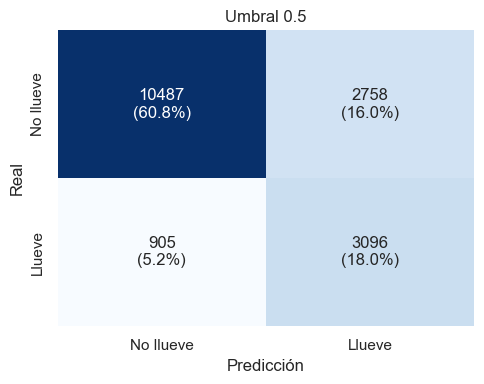

In [33]:
CLASES = ['No llueve', 'Llueve']


def graficar_matrices(y_real, predicciones):
    """Grafica una matriz de confusión por modelo, con la cantidad y el porcentaje sobre el total."""
    fig, axes = plt.subplots(1, len(predicciones), figsize=(5 * len(predicciones), 4), squeeze=False)
    for ax, (nombre, y_pred) in zip(axes[0], predicciones.items()):
        matriz = confusion_matrix(y_real, y_pred)
        etiquetas = [[f'{n}\n({n / matriz.sum():.1%})' for n in fila] for fila in matriz]
        sns.heatmap(matriz, annot=etiquetas, fmt='', cmap='Blues', cbar=False,
                    xticklabels=CLASES, yticklabels=CLASES, ax=ax)
        ax.set(title=nombre, xlabel='Predicción', ylabel='Real')
    plt.tight_layout()
    plt.show()


graficar_matrices(y_test, {'Umbral 0.5': (prob_test >= 0.5).astype(int)})

Con umbral 0.5, el modelo detecta el 77.4 % de los días con lluvia (recall), pero solo el 52.9 % de sus avisos son
correctos (precisión). Hay 2758 falsas alarmas (16.0 % de los días) y 905 lluvias sin avisar (5.2 %).

- Falso positivo: anuncia lluvia y no llueve. Por ejemplo, alguien suspende una actividad sin necesidad.
- Falso negativo: no anuncia lluvia y llueve. Alguien queda expuesto sin estar preparado.

### 2.2 Curva ROC y umbral de decisión

El modelo da una probabilidad y predice lluvia cuando llega al umbral. El 0.5 es el valor por defecto, pero no
tiene por qué ser el mejor (clase 7).

Para elegirlo usamos la curva precisión-recall en validación: cada umbral da un punto con su recall y su
precisión, y el área bajo la curva es la "AUC precisión-recall" de la tabla de métricas. Elegimos el punto donde la
curva corta la diagonal, en el que la precisión es igual al recall: no favorece a ninguno de los dos errores.

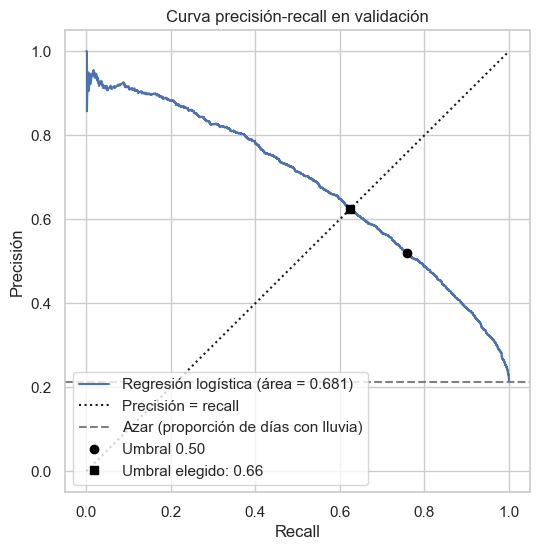

Umbral 0.50: precisión 0.520, recall 0.758
Umbral 0.66: precisión 0.625, recall 0.625


In [34]:
# Curva precisión-recall en validación: cada umbral da un punto (recall, precisión)
precisiones, recalls, umbrales = precision_recall_curve(y_val, prob_val)

# Elegimos el umbral donde la precisión es igual al recall, es decir, donde la curva corta la diagonal
i = np.argmin(np.abs(precisiones[:-1] - recalls[:-1]))
umbral = round(float(umbrales[i]), 2)
j = np.argmin(np.abs(umbrales - 0.5))

plt.figure(figsize=(6, 6))
plt.plot(recalls, precisiones, label=f'Regresión logística (área = {average_precision_score(y_val, prob_val):.3f})')
plt.plot([0, 1], [0, 1], 'k:', label='Precisión = recall')
plt.axhline(y_val.mean(), color='gray', linestyle='--', label='Azar (proporción de días con lluvia)')
plt.plot(recalls[j], precisiones[j], 'o', color='black', label='Umbral 0.50')
plt.plot(recalls[i], precisiones[i], 's', color='black', label=f'Umbral elegido: {umbral:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precisión')
plt.title('Curva precisión-recall en validación')
plt.legend(loc='lower left')
plt.show()
print(f'Umbral 0.50: precisión {precisiones[j]:.3f}, recall {recalls[j]:.3f}')
print(f'Umbral {umbral:.2f}: precisión {precisiones[i]:.3f}, recall {recalls[i]:.3f}')

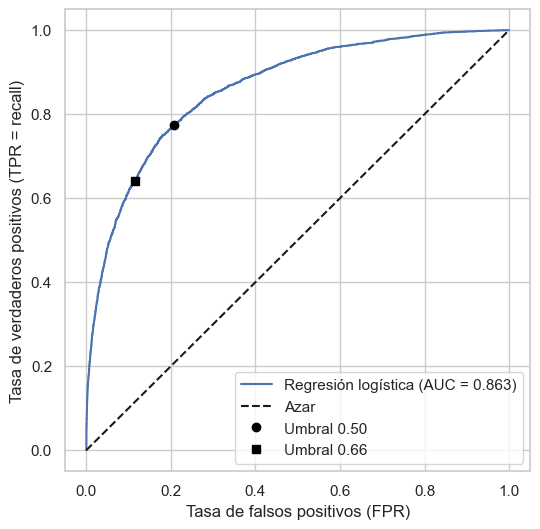

In [35]:
# Curva ROC en prueba, con el punto que corresponde a cada umbral
fpr, tpr, _ = roc_curve(y_test, prob_test)
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'Regresión logística (AUC = {roc_auc_score(y_test, prob_test):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Azar')
for u, marcador in [(0.5, 'o'), (umbral, 's')]:
    tn, fp, fn, tp = confusion_matrix(y_test, (prob_test >= u).astype(int)).ravel()
    plt.plot(fp / (fp + tn), tp / (tp + fn), marcador, color='black', label=f'Umbral {u:.2f}')
plt.xlabel('Tasa de falsos positivos (FPR)')
plt.ylabel('Tasa de verdaderos positivos (TPR = recall)')
plt.legend(loc='lower right')
plt.show()

,Accuracy,Accuracy balanceada,Precisión,Recall,F1,AUC ROC,AUC precisión-recall
Umbral 0.5,0.788,0.783,0.529,0.774,0.628,0.863,0.7
Umbral 0.66,0.829,0.764,0.629,0.642,0.635,0.863,0.7


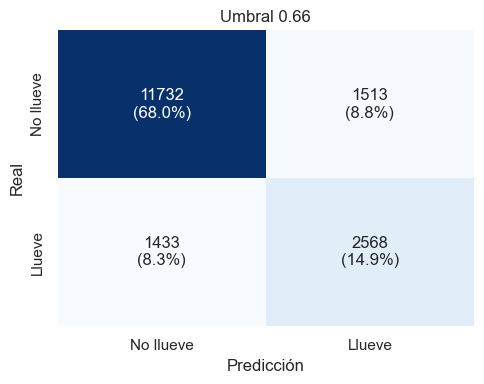

In [36]:
# Métricas en prueba con el umbral 0.5 y con el elegido en validación
display(pd.DataFrame({'Umbral 0.5': metricas(y_test, prob_test),
                      f'Umbral {umbral:.2f}': metricas(y_test, prob_test, umbral)}).T.round(3))

graficar_matrices(y_test, {f'Umbral {umbral:.2f}': (prob_test >= umbral).astype(int)})

- ¿Es 0.5 el mejor umbral? Para nuestro criterio, no. En validación, con 0.5 el recall es 0.758 pero la precisión
  baja a 0.520; en el umbral elegido, 0.66, las dos valen 0.625. En prueba, con 0.66 la
  precisión sube de 0.529 a 0.629 y el recall baja de 0.774 a 0.642; el F1 mejora de 0.628 a 0.635, y las falsas
  alarmas bajan de 2758 a 1513.
- En la curva ROC, subir el umbral mueve el punto hacia abajo y a la izquierda: menos falsas alarmas y menos lluvias
  detectadas. El AUC (0.863) es el mismo para cualquier umbral.
- El umbral adecuado depende de cuánto cuesta cada error. Si no avisar una lluvia fuera mucho más grave que una
  falsa alarma, convendría uno más bajo.

### 2.3 ¿Conseguimos un buen ajuste?

In [37]:
# Mismas métricas en los tres conjuntos, con el umbral elegido
pd.DataFrame({'Entrenamiento': metricas(y_train, modelo.predict_proba(X_train_prep)[:, 1], umbral),
              'Validación': metricas(y_val, prob_val, umbral),
              'Prueba': metricas(y_test, prob_test, umbral)}).T.round(3)

,Accuracy,Accuracy balanceada,Precisión,Recall,F1,AUC ROC,AUC precisión-recall
Entrenamiento,0.839,0.774,0.638,0.656,0.647,0.877,0.715
Validación,0.842,0.762,0.630,0.622,0.626,0.870,0.681
Prueba,0.829,0.764,0.629,0.642,0.635,0.863,0.700


Las métricas son parecidas en los tres conjuntos (F1 de 0.647, 0.626 y 0.635; AUC ROC de 0.877, 0.870 y 0.863): no
hay sobreajuste, porque el modelo rinde casi igual en años que no vio. Pero el F1 no pasa de 0.65 ni siquiera en
entrenamiento: una frontera lineal no alcanza para separar clases que se superponen tanto (sección 1.7). Hay algo de
subajuste: el modelo generaliza bien, pero tiene margen para mejorar.

## 3. Modelo base

Un modelo base es un modelo simple, que casi no aprende, y sirve de piso: el modelo tiene que superarlo por un
margen que valga la pena (clase 11). Usamos dos de los que propone la clase:

- Mayoría: predice siempre "no llueve".
- Persistencia: llueve mañana si llovió hoy (`RainToday`). Es el modelo base habitual en series de tiempo. Si falta
  `RainToday`, predice que no llueve.

Repetimos las métricas, las matrices de confusión y la curva ROC del ítem 2. No elegimos umbral, porque predicen
directamente 0 o 1, ni analizamos el ajuste, porque no se entrenan.

In [38]:
# Los dos modelos base predicen directamente 0 o 1
pred_mayoria = np.zeros(len(y_test), dtype=int)  # siempre "no llueve"
pred_persistencia = (X_test['RainToday'] == 'Yes').astype(int).to_numpy()  # llueve mañana si llovió hoy

pd.DataFrame({f'Regresión logística (umbral {umbral:.2f})': metricas(y_test, prob_test, umbral),
              'Base: mayoría': metricas(y_test, pred_mayoria),
              'Base: persistencia': metricas(y_test, pred_persistencia)}).T.round(3)

,Accuracy,Accuracy balanceada,Precisión,Recall,F1,AUC ROC,AUC precisión-recall
Regresión logística (umbral 0.66),0.829,0.764,0.629,0.642,0.635,0.863,0.700
Base: mayoría,0.768,0.500,0.000,0.000,0.000,0.500,0.232
Base: persistencia,0.744,0.640,0.449,0.444,0.446,0.640,0.328


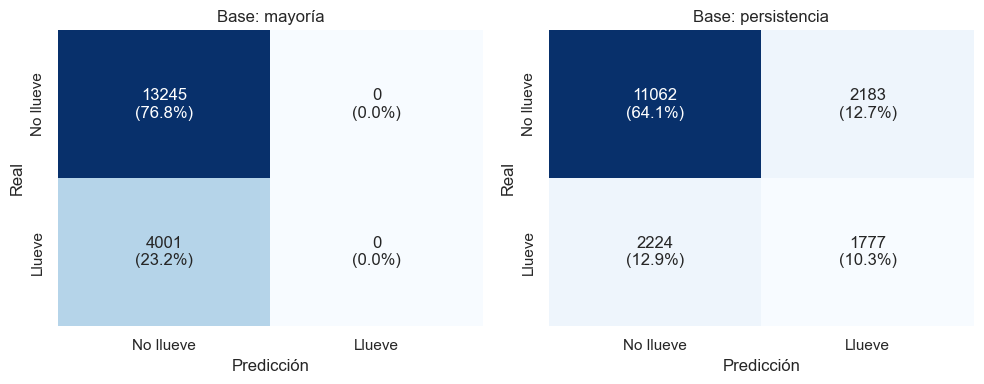

In [39]:
graficar_matrices(y_test, {'Base: mayoría': pred_mayoria, 'Base: persistencia': pred_persistencia})

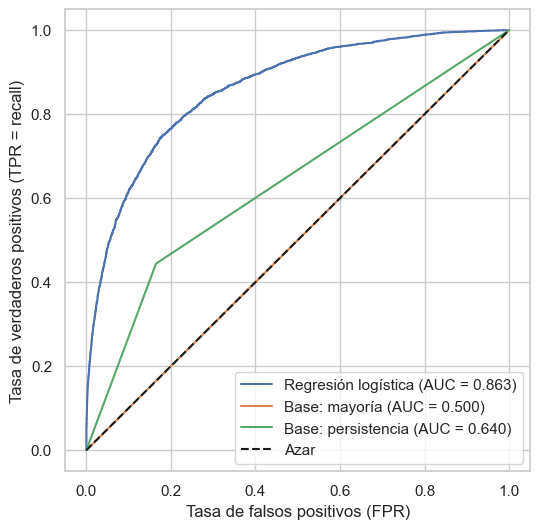

In [40]:
# Curvas ROC en prueba. La persistencia aporta un solo punto, porque predice 0 o 1
plt.figure(figsize=(6, 6))
for nombre, prob in [('Regresión logística', prob_test), ('Base: mayoría', pred_mayoria),
                     ('Base: persistencia', pred_persistencia)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC = {roc_auc_score(y_test, prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Azar')
plt.xlabel('Tasa de falsos positivos (FPR)')
plt.ylabel('Tasa de verdaderos positivos (TPR = recall)')
plt.legend(loc='lower right')
plt.show()

- Mayoría: su accuracy (0.768) es más alta que la de la persistencia (0.744), pero no detecta ninguna lluvia
  (recall y F1 de 0). Muestra por qué la accuracy no sirve con clases desbalanceadas. Su curva ROC es la diagonal.
- Persistencia: detecta el 44.4 % de las lluvias y acierta en el 44.9 % de sus avisos (F1 de 0.446).
- La regresión logística supera a los dos en todas las métricas: el F1 pasa de 0.446 a 0.635, y el área bajo la
  curva precisión-recall, de 0.328 a 0.700.